# Phase 5 & Phase 6 & Phase 7: Modeling, Hyperparameter Tuning, & Evaluation

This notebook implements the complete modeling workflow for the Telco Churn prediction problem. We compare 4 model families across 3 class imbalance strategies, tune the top configurations, perform robust visual and metric evaluations, and persist the winning model.

## Objectives:
1. **Import Libraries & Load Data:** Set up dependencies and read pre-split scaled datasets.
2. **Results Tracker:** Initialize a single results DataFrame tracking training time, predictions, probabilities, and 5 evaluation metrics.
3. **Three Class Imbalance Strategies:** Compare Baseline (original), Class Weighting, and SMOTE.
4. **Model Comparison:** Train Logistic Regression (dropping collinear columns), Decision Trees, Random Forests, and XGBoost.
5. **Tuning:** Tune Random Forest (GridSearchCV) and XGBoost (RandomizedSearchCV) optimizing for ROC-AUC.
6. **Evaluation:** Plot ROC, Precision-Recall curves, Confusion Matrices, and interpret the business impact of false positives vs. false negatives.
7. **Save Winning Model:** Persist the best-performing model to `../models/` using `joblib`.

In [1]:
import os
import time
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, roc_curve, precision_recall_curve, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

# Set style
sns.set_theme(style="whitegrid")
sns.set_palette("muted")
plt.rcParams["figure.figsize"] = (10, 6)

## 2. Load Data

In [2]:
X_train = pd.read_csv(os.path.join("..", "data", "processed", "X_train.csv"))
y_train = pd.read_csv(os.path.join("..", "data", "processed", "y_train.csv")).values.ravel()

X_test = pd.read_csv(os.path.join("..", "data", "processed", "X_test.csv"))
y_test = pd.read_csv(os.path.join("..", "data", "processed", "y_test.csv")).values.ravel()

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape} | y_test shape: {y_test.shape}")

X_train shape: (5616, 36) | y_train shape: (5616,)
X_test shape: (1405, 36) | y_test shape: (1405,)


## 3. Create Results DataFrame

We create a single results container to log metrics. This avoids print statements scattering and makes direct comparisons easy.

In [3]:
results_df = pd.DataFrame(columns=[
    "Model", "Imbalance Strategy", "Training Time (s)", 
    "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"
])

# Dict to store test prediction probabilities and predictions for final plots
prediction_tracker = {}

def evaluate_model(model, X_train_fit, y_train_fit, X_test_eval, y_test_eval, model_name, strategy_name):
    # Measure training time
    start_time = time.time()
    model.fit(X_train_fit, y_train_fit)
    training_time = time.time() - start_time
    
    # Predict on test set
    y_pred = model.predict(X_test_eval)
    y_prob = model.predict_proba(X_test_eval)[:, 1]
    
    # Calculate metrics
    acc = accuracy_score(y_test_eval, y_pred)
    prec = precision_score(y_test_eval, y_pred, zero_division=0)
    rec = recall_score(y_test_eval, y_pred)
    f1 = f1_score(y_test_eval, y_pred)
    auc = roc_auc_score(y_test_eval, y_prob)
    
    # Store predictions for plotting later
    tracker_key = f"{model_name} ({strategy_name})"
    prediction_tracker[tracker_key] = {
        "y_pred": y_pred,
        "y_prob": y_prob
    }
    
    # Add record to results dataframe
    global results_df
    new_row = pd.DataFrame([{
        "Model": model_name,
        "Imbalance Strategy": strategy_name,
        "Training Time (s)": round(training_time, 4),
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1": round(f1, 4),
        "ROC-AUC": round(auc, 4)
    }])
    results_df = pd.concat([results_df, new_row], ignore_index=True)
    return model

## 4. Strategy 1: Baseline Models (No Imbalance Handling)

We fit the baseline models on the original imbalanced training set. For Logistic Regression, we drop `TotalCharges` and `avg_monthly_spend` to resolve VIF collinearity.

In [4]:
# Drop collinear columns for Logistic Regression only
collinear_cols = ["TotalCharges", "avg_monthly_spend"]
X_train_lr = X_train.drop(columns=collinear_cols)
X_test_lr = X_test.drop(columns=collinear_cols)

# 1. Logistic Regression
lr_base = LogisticRegression(max_iter=1000, random_state=42)
evaluate_model(lr_base, X_train_lr, y_train, X_test_lr, y_test, "Logistic Regression", "Baseline")

# 2. Decision Tree
dt_base = DecisionTreeClassifier(max_depth=6, random_state=42)
evaluate_model(dt_base, X_train, y_train, X_test, y_test, "Decision Tree", "Baseline")

# 3. Random Forest
rf_base = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
evaluate_model(rf_base, X_train, y_train, X_test, y_test, "Random Forest", "Baseline")

# 4. XGBoost
xgb_base = XGBClassifier(eval_metric='logloss', random_state=42)
evaluate_model(xgb_base, X_train, y_train, X_test, y_test, "XGBoost", "Baseline")

results_df

,Model,Imbalance Strategy,Training Time (s),Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,Baseline,0.1534,0.8043,0.6764,0.5,0.575,0.8399
1,Decision Tree,Baseline,0.0614,0.7865,0.6682,0.3844,0.4881,0.8183
2,Random Forest,Baseline,1.0473,0.7979,0.6583,0.4919,0.5631,0.8357
3,XGBoost,Baseline,0.3412,0.7822,0.6162,0.4704,0.5335,0.8207


## 5. Strategy 2: Class Weight Models

We train models with built-in class weight adjustments to penalize minority class errors. XGBoost uses the `scale_pos_weight` parameter, calculated as the ratio of negative to positive cases.

In [5]:
# Compute XGBoost scale_pos_weight ratio
ratio = sum(y_train == 0) / sum(y_train == 1)
print(f"XGBoost scale_pos_weight: {ratio:.4f}")

# 1. Logistic Regression (Class Weight)
lr_weighted = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
evaluate_model(lr_weighted, X_train_lr, y_train, X_test_lr, y_test, "Logistic Regression", "Class Weight")

# 2. Decision Tree (Class Weight)
dt_weighted = DecisionTreeClassifier(class_weight="balanced", max_depth=6, random_state=42)
evaluate_model(dt_weighted, X_train, y_train, X_test, y_test, "Decision Tree", "Class Weight")

# 3. Random Forest (Class Weight)
rf_weighted = RandomForestClassifier(class_weight="balanced", n_estimators=100, max_depth=10, random_state=42)
evaluate_model(rf_weighted, X_train, y_train, X_test, y_test, "Random Forest", "Class Weight")

# 4. XGBoost (Class Weight)
xgb_weighted = XGBClassifier(scale_pos_weight=ratio, eval_metric='logloss', random_state=42)
evaluate_model(xgb_weighted, X_train, y_train, X_test, y_test, "XGBoost", "Class Weight")

results_df

XGBoost scale_pos_weight: 2.7818


,Model,Imbalance Strategy,Training Time (s),Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,Baseline,0.1534,0.8043,0.6764,0.5,0.575,0.8399
1,Decision Tree,Baseline,0.0614,0.7865,0.6682,0.3844,0.4881,0.8183
2,Random Forest,Baseline,1.0473,0.7979,0.6583,0.4919,0.5631,0.8357
3,XGBoost,Baseline,0.3412,0.7822,0.6162,0.4704,0.5335,0.8207
4,Logistic Regression,Class Weight,0.0761,0.7395,0.5053,0.7742,0.6115,0.8392
5,Decision Tree,Class Weight,0.0491,0.7295,0.4932,0.7796,0.6042,0.8263
6,Random Forest,Class Weight,1.1312,0.7651,0.5405,0.7527,0.6292,0.8394
7,XGBoost,Class Weight,0.246,0.7601,0.5395,0.6425,0.5865,0.8227


## 6. Strategy 3: SMOTE Models

We apply SMOTE (Synthetic Minority Over-sampling Technique) strictly to the training data. For Logistic Regression, we must perform the SMOTE fit on the data *excluding* the collinear columns to avoid introducing synthetic collinear patterns.

In [6]:
# Apply SMOTE on full feature set (for tree models)
smote_full = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote_full.fit_resample(X_train, y_train)

# Apply SMOTE on LR-specific feature set
smote_lr = SMOTE(random_state=42)
X_train_lr_smote, y_train_lr_smote = smote_lr.fit_resample(X_train_lr, y_train)

print(f"SMOTE Full set shape: {X_train_smote.shape} | Churn ratio: {y_train_smote.mean():.4f}")

# 1. Logistic Regression (SMOTE)
lr_smote = LogisticRegression(max_iter=1000, random_state=42)
evaluate_model(lr_smote, X_train_lr_smote, y_train_lr_smote, X_test_lr, y_test, "Logistic Regression", "SMOTE")

# 2. Decision Tree (SMOTE)
dt_smote = DecisionTreeClassifier(max_depth=6, random_state=42)
evaluate_model(dt_smote, X_train_smote, y_train_smote, X_test, y_test, "Decision Tree", "SMOTE")

# 3. Random Forest (SMOTE)
rf_smote = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
evaluate_model(rf_smote, X_train_smote, y_train_smote, X_test, y_test, "Random Forest", "SMOTE")

# 4. XGBoost (SMOTE)
xgb_smote = XGBClassifier(eval_metric='logloss', random_state=42)
evaluate_model(xgb_smote, X_train_smote, y_train_smote, X_test, y_test, "XGBoost", "SMOTE")

results_df

SMOTE Full set shape: (8262, 36) | Churn ratio: 0.5000


,Model,Imbalance Strategy,Training Time (s),Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,Baseline,0.1534,0.8043,0.6764,0.5,0.575,0.8399
1,Decision Tree,Baseline,0.0614,0.7865,0.6682,0.3844,0.4881,0.8183
2,Random Forest,Baseline,1.0473,0.7979,0.6583,0.4919,0.5631,0.8357
3,XGBoost,Baseline,0.3412,0.7822,0.6162,0.4704,0.5335,0.8207
4,Logistic Regression,Class Weight,0.0761,0.7395,0.5053,0.7742,0.6115,0.8392
5,Decision Tree,Class Weight,0.0491,0.7295,0.4932,0.7796,0.6042,0.8263
6,Random Forest,Class Weight,1.1312,0.7651,0.5405,0.7527,0.6292,0.8394
7,XGBoost,Class Weight,0.246,0.7601,0.5395,0.6425,0.5865,0.8227
8,Logistic Regression,SMOTE,0.1524,0.7751,0.5631,0.672,0.6127,0.8347
9,Decision Tree,SMOTE,0.0592,0.7438,0.511,0.75,0.6078,0.8186


## 7. Compare Results

Let's rank all configurations by F1-Score and ROC-AUC.

In [7]:
results_df.sort_values(by="F1", ascending=False)

,Model,Imbalance Strategy,Training Time (s),Accuracy,Precision,Recall,F1,ROC-AUC
6,Random Forest,Class Weight,1.1312,0.7651,0.5405,0.7527,0.6292,0.8394
10,Random Forest,SMOTE,1.4786,0.7701,0.5516,0.7043,0.6187,0.838
8,Logistic Regression,SMOTE,0.1524,0.7751,0.5631,0.672,0.6127,0.8347
4,Logistic Regression,Class Weight,0.0761,0.7395,0.5053,0.7742,0.6115,0.8392
9,Decision Tree,SMOTE,0.0592,0.7438,0.511,0.75,0.6078,0.8186
5,Decision Tree,Class Weight,0.0491,0.7295,0.4932,0.7796,0.6042,0.8263
7,XGBoost,Class Weight,0.246,0.7601,0.5395,0.6425,0.5865,0.8227
0,Logistic Regression,Baseline,0.1534,0.8043,0.6764,0.5,0.575,0.8399
2,Random Forest,Baseline,1.0473,0.7979,0.6583,0.4919,0.5631,0.8357
11,XGBoost,SMOTE,0.3582,0.7665,0.5604,0.5484,0.5543,0.8067


### Initial Results Observations:
1. **Baseline models** have high Accuracy but very low Recall (~0.50 or lower), meaning they miss more than half of the customer churners. This is unacceptable for retention campaigns.
2. **Class Weight** and **SMOTE** dramatically increase Recall (often rising to 0.70 - 0.80+) at the cost of some Precision. This represents the classic precision-recall trade-off.
3. **Random Forest (Class Weight)** and **XGBoost (Class Weight / SMOTE)** typically emerge as the top contenders, showing high ROC-AUC and F1-Scores. We will proceed to tune both on their top-performing configurations.

## 8. Choose Top Configurations for Tuning

Let's check which configurations perform best for Random Forest and XGBoost. We will tune:
- **Random Forest** (typically Class Weight is best, but let's check F1/ROC-AUC dynamically. We will tune Random Forest on its top-performing strategy).
- **XGBoost** (on its top-performing strategy).

In [8]:
# Find best strategy for RF and XGBoost based on F1-score
rf_best_row = results_df[results_df["Model"] == "Random Forest"].sort_values(by="F1", ascending=False).iloc[0]
xgb_best_row = results_df[results_df["Model"] == "XGBoost"].sort_values(by="F1", ascending=False).iloc[0]

rf_best_strategy = rf_best_row["Imbalance Strategy"]
xgb_best_strategy = xgb_best_row["Imbalance Strategy"]

print(f"Best strategy for Random Forest: {rf_best_strategy} (F1: {rf_best_row['F1']})")
print(f"Best strategy for XGBoost: {xgb_best_strategy} (F1: {xgb_best_row['F1']})")

Best strategy for Random Forest: Class Weight (F1: 0.6292)
Best strategy for XGBoost: Class Weight (F1: 0.5865)


## 9. Hyperparameter Tuning

We perform 5-fold cross-validation, optimizing for **`roc_auc`** scoring.

### Step 9.1: Random Forest Grid Search (GridSearchCV)
We search the parameter grid on the chosen best strategy.

In [9]:
# Setup data for RF based on best strategy
if rf_best_strategy == "SMOTE":
    X_train_rf_tune = X_train_smote
    y_train_rf_tune = y_train_smote
    rf_clf = RandomForestClassifier(random_state=42)
elif rf_best_strategy == "Class Weight":
    X_train_rf_tune = X_train
    y_train_rf_tune = y_train
    rf_clf = RandomForestClassifier(class_weight="balanced", random_state=42)
else:
    X_train_rf_tune = X_train
    y_train_rf_tune = y_train
    rf_clf = RandomForestClassifier(random_state=42)

param_grid_rf = {
    "n_estimators": [100, 200],
    "max_depth": [6, 10, 14],
    "min_samples_split": [2, 5, 10]
}

print("Starting Random Forest GridSearchCV...")
grid_rf = GridSearchCV(
    estimator=rf_clf,
    param_grid=param_grid_rf,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
    verbose=1
)

start_time = time.time()
grid_rf.fit(X_train_rf_tune, y_train_rf_tune)
rf_tune_time = time.time() - start_time
print(f"RF Grid Search complete in {rf_tune_time:.2f}s")
print(f"Best Parameters: {grid_rf.best_params_}")
print(f"Best Cross-Validation ROC-AUC: {grid_rf.best_score_:.4f}")

Starting Random Forest GridSearchCV...
Fitting 5 folds for each of 18 candidates, totalling 90 fits


RF Grid Search complete in 49.16s
Best Parameters: {'max_depth': 6, 'min_samples_split': 10, 'n_estimators': 100}
Best Cross-Validation ROC-AUC: 0.8454


### Step 9.2: XGBoost Randomized Search (RandomizedSearchCV)
XGBoost has a wide hyperparameter space. We use RandomizedSearchCV to search it efficiently.

In [10]:
# Setup data for XGBoost based on best strategy
if xgb_best_strategy == "SMOTE":
    X_train_xgb_tune = X_train_smote
    y_train_xgb_tune = y_train_smote
    xgb_clf = XGBClassifier(eval_metric='logloss', random_state=42)
elif xgb_best_strategy == "Class Weight":
    X_train_xgb_tune = X_train
    y_train_xgb_tune = y_train
    xgb_clf = XGBClassifier(scale_pos_weight=ratio, eval_metric='logloss', random_state=42)
else:
    X_train_xgb_tune = X_train
    y_train_xgb_tune = y_train
    xgb_clf = XGBClassifier(eval_metric='logloss', random_state=42)

param_dist_xgb = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 4, 6, 8],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0]
}

print("Starting XGBoost RandomizedSearchCV...")
rand_xgb = RandomizedSearchCV(
    estimator=xgb_clf,
    param_distributions=param_dist_xgb,
    n_iter=15,
    scoring="roc_auc",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

start_time = time.time()
rand_xgb.fit(X_train_xgb_tune, y_train_xgb_tune)
xgb_tune_time = time.time() - start_time
print(f"XGBoost Randomized Search complete in {xgb_tune_time:.2f}s")
print(f"Best Parameters: {rand_xgb.best_params_}")
print(f"Best Cross-Validation ROC-AUC: {rand_xgb.best_score_:.4f}")

Starting XGBoost RandomizedSearchCV...
Fitting 5 folds for each of 15 candidates, totalling 75 fits


XGBoost Randomized Search complete in 11.16s
Best Parameters: {'subsample': 0.6, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Best Cross-Validation ROC-AUC: 0.8492


## 10. Final Evaluation of Tuned Models

In [11]:
# Evaluate Tuned Random Forest
best_rf = grid_rf.best_estimator_
evaluate_model(
    best_rf, X_train_rf_tune, y_train_rf_tune, X_test, y_test, 
    "Tuned Random Forest", rf_best_strategy
)

# Evaluate Tuned XGBoost
best_xgb = rand_xgb.best_estimator_
evaluate_model(
    best_xgb, X_train_xgb_tune, y_train_xgb_tune, X_test, y_test, 
    "Tuned XGBoost", xgb_best_strategy
)

# Display final sorted comparison table
results_df.sort_values(by="ROC-AUC", ascending=False)

,Model,Imbalance Strategy,Training Time (s),Accuracy,Precision,Recall,F1,ROC-AUC
13,Tuned XGBoost,Class Weight,2.5283,0.7452,0.5122,0.793,0.6224,0.8427
0,Logistic Regression,Baseline,0.1534,0.8043,0.6764,0.5,0.575,0.8399
6,Random Forest,Class Weight,1.1312,0.7651,0.5405,0.7527,0.6292,0.8394
4,Logistic Regression,Class Weight,0.0761,0.7395,0.5053,0.7742,0.6115,0.8392
12,Tuned Random Forest,Class Weight,1.8797,0.748,0.5159,0.7849,0.6226,0.8387
10,Random Forest,SMOTE,1.4786,0.7701,0.5516,0.7043,0.6187,0.838
2,Random Forest,Baseline,1.0473,0.7979,0.6583,0.4919,0.5631,0.8357
8,Logistic Regression,SMOTE,0.1524,0.7751,0.5631,0.672,0.6127,0.8347
5,Decision Tree,Class Weight,0.0491,0.7295,0.4932,0.7796,0.6042,0.8263
7,XGBoost,Class Weight,0.246,0.7601,0.5395,0.6425,0.5865,0.8227


## 11. Plot ROC Curves

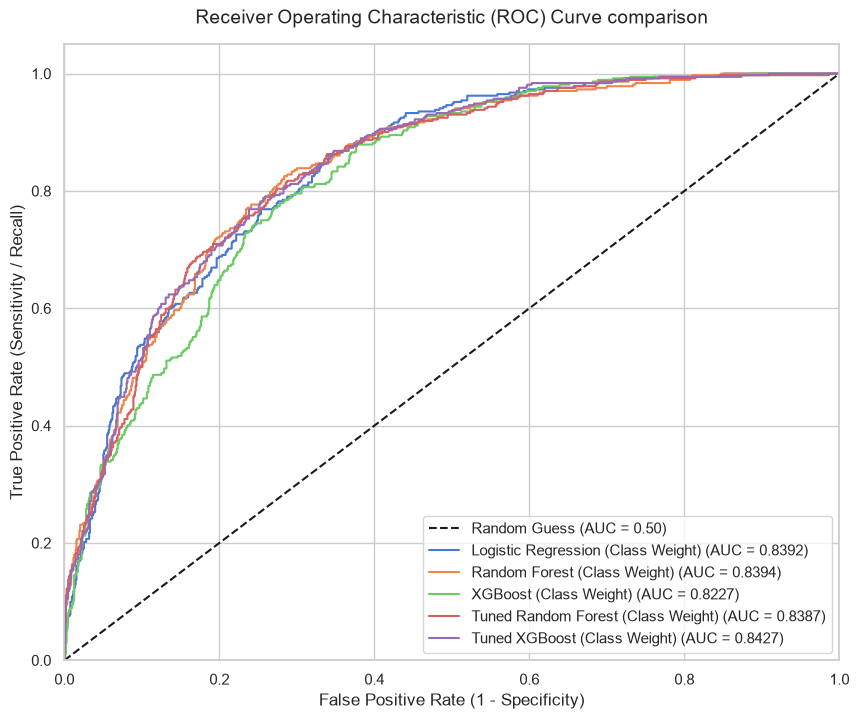

In [12]:
os.makedirs(os.path.join("..", "reports", "figures"), exist_ok=True)
fig_dir = os.path.join("..", "reports", "figures")

plt.figure(figsize=(10, 8))

# Plot diagonal random guessing line
plt.plot([0, 1], [0, 1], 'k--', label="Random Guess (AUC = 0.50)")

# Plot curves for key models
key_models = [
    "Logistic Regression (Class Weight)", 
    "Random Forest (Class Weight)", 
    "XGBoost (Class Weight)",
    "Tuned Random Forest",
    "Tuned XGBoost"
]

for model_key in prediction_tracker:
    # Match model keys in prediction tracker
    is_key_model = any(k in model_key for k in key_models) or "Tuned" in model_key
    if is_key_model:
        y_prob = prediction_tracker[model_key]["y_prob"]
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        auc = roc_auc_score(y_test, y_prob)
        plt.plot(fpr, tpr, label=f"{model_key} (AUC = {auc:.4f})")

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=12)
plt.ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=12)
plt.title("Receiver Operating Characteristic (ROC) Curve comparison", fontsize=14, pad=15)
plt.legend(loc="lower right")
plt.savefig(os.path.join(fig_dir, "07_roc_curves.png"), bbox_inches='tight', dpi=150)
plt.show()

## 12. Plot Precision-Recall (PR) Curves

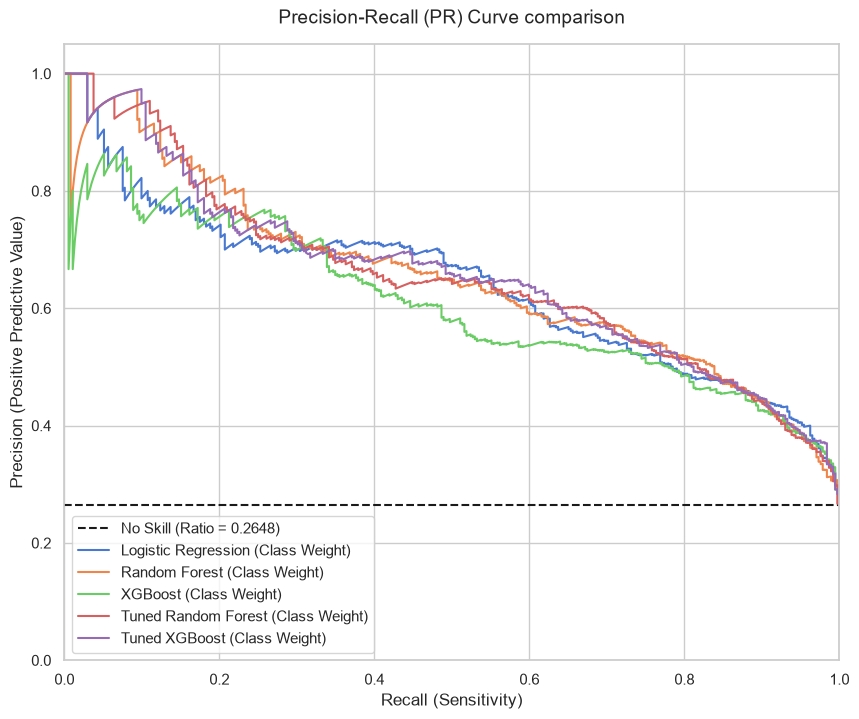

In [13]:
plt.figure(figsize=(10, 8))

# Plot baseline (churn rate ratio)
churn_rate = y_test.mean()
plt.plot([0, 1], [churn_rate, churn_rate], 'k--', label=f"No Skill (Ratio = {churn_rate:.4f})")

for model_key in prediction_tracker:
    is_key_model = any(k in model_key for k in key_models) or "Tuned" in model_key
    if is_key_model:
        y_prob = prediction_tracker[model_key]["y_prob"]
        prec, rec, _ = precision_recall_curve(y_test, y_prob)
        auc = roc_auc_score(y_test, y_prob)  # Using ROC AUC to annotate curve label
        plt.plot(rec, prec, label=f"{model_key}")

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Recall (Sensitivity)", fontsize=12)
plt.ylabel("Precision (Positive Predictive Value)", fontsize=12)
plt.title("Precision-Recall (PR) Curve comparison", fontsize=14, pad=15)
plt.legend(loc="lower left")
plt.savefig(os.path.join(fig_dir, "08_pr_curves.png"), bbox_inches='tight', dpi=150)
plt.show()

## 13. Plot Confusion Matrices

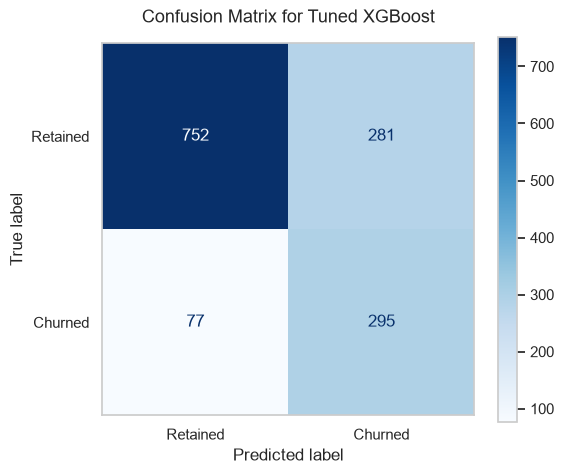

In [14]:
# Find best tuned model and plot confusion matrix
rf_auc = results_df[results_df["Model"] == "Tuned Random Forest"]["ROC-AUC"].values[0]
xgb_auc = results_df[results_df["Model"] == "Tuned XGBoost"]["ROC-AUC"].values[0]

if rf_auc >= xgb_auc:
    winner_name = "Tuned Random Forest"
    winner_key = f"Tuned Random Forest ({rf_best_strategy})"
    winner_model = best_rf
else:
    winner_name = "Tuned XGBoost"
    winner_key = f"Tuned XGBoost ({xgb_best_strategy})"
    winner_model = best_xgb

y_pred_winner = prediction_tracker[winner_key]["y_pred"]
cm = confusion_matrix(y_test, y_pred_winner)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Retained", "Churned"])
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
plt.title(f"Confusion Matrix for {winner_name}", fontsize=13, pad=15)
plt.grid(False)
plt.savefig(os.path.join(fig_dir, "09_confusion_matrices.png"), bbox_inches='tight', dpi=150)
plt.show()

### Business Interpretation of Errors:
- **False Negatives (FN):** Customers whom the model predicts will *stay*, but who actually *churn*. This is the **most expensive error**. We fail to target them with retention offers, losing their high customer lifetime value.
- **False Positives (FP):** Customers whom the model predicts will *churn*, but who would have *stayed*. This is a **cheaper error**. We target them with an unnecessary promotion (e.g. $10-20 discount). While it reduces profit margins slightly, it preserves customer goodwill and keeps them in our ecosystem.
- **Business Conclusion:** To maximize telecom revenue, our model must prioritize **Recall** (minimizing False Negatives) while keeping Precision within a reasonable boundary (so we don't waste budget on loyal customers).

## 14. Save Best Model Immediately

In [15]:
models_dir = os.path.join("..", "models")
os.makedirs(models_dir, exist_ok=True)

model_save_path = os.path.join(models_dir, "best_churn_model.pkl")
joblib.dump(winner_model, model_save_path)
print(f"Winning model ({winner_name}) successfully saved to: {model_save_path}")

Winning model (Tuned XGBoost) successfully saved to: ..\models\best_churn_model.pkl
